# Delta Air Lines: Flight Delay Prediction

**Applied Machine Learning - Fall 2026**

**Business question:** How can Delta Air Lines use historical flight information to anticipate arrival delays and support proactive operational decision-making?

**Machine learning question:** Using only information available before scheduled departure, how accurately can we predict whether a Delta-operated flight will arrive at least 15 minutes late, and which pre-departure flight characteristics are most predictive of delay risk?

**Scope:** U.S. BTS Reporting Carrier On-Time Performance records for 2025. We predict `ARR_DEL15` for completed flights with observed arrival outcomes. 

**Prediction timing:** Before scheduled departure. Actual departure/arrival outcomes must never be predictors.

This notebook shows every step from raw data to models: loading the data (Section 2), checking its quality (Section 3), cleaning it and making features (Section 4), and preparing it for the models (Section 5). All findings are based on the output shown below.


#LAD OS KIGGE PÅ DENNE START IGEN INDEN VI AFLEVERER, HVIS DER SKAL TILFØJES NOGET ELLER MANGLER NOGET

## 1. Import libraries and set the file paths

We load the Python libraries we need and point to the 12 monthly data files. The notebook must be run from the folder where both this notebook and the `data/` folder are placed. If a file is missing, the cell stops with an error that names the missing file.

In [2]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

DATA_DIR = Path("data")
MONTHLY_FILES = [DATA_DIR / f"{month:02d}-2025.csv" for month in range(1, 13)]

missing_files = [str(path) for path in MONTHLY_FILES if not path.is_file()]
if missing_files:
    raise FileNotFoundError(f"Missing BTS monthly file(s): {missing_files}")

print(f"Found all {len(MONTHLY_FILES)} monthly files.")

Found all 12 monthly files.


## 2. Data collection

We downloaded the 2025 flight data from the U.S. Bureau of Transportation Statistics (BTS) as 12 monthly files and stacked them into one table. To keep the data small, we only read the 11 columns we need from each file, and we only keep flights operated by Delta (DL). For each month we print the total number of flights and the number of Delta flights, so it is clear how the dataset was built. At the end, we check that all 12 months are there.

This is described in Section 2.1 of the report.

In [3]:
# the 11 columns we need, grouped in 4 categories
EXPECTED_COLUMNS = [
    # Flight Information
    "FL_DATE", "OP_UNIQUE_CARRIER", "ORIGIN", "DEST",
    # Schedule
    "CRS_DEP_TIME", "CRS_ARR_TIME", "CRS_ELAPSED_TIME", "DISTANCE",
    # Flight Status
    "CANCELLED", "DIVERTED",
    # Outcome (target)
    "ARR_DEL15",
]

# an empty list where we save the Delta flights from each month
monthly_delta = []

# going through the 12 monthly files one by one
for file_path in MONTHLY_FILES:
    # reading only the 11 columns we need
    monthly = pd.read_csv(file_path, usecols=EXPECTED_COLUMNS)

    # keeping only flights operated by Delta (DL)
    delta = monthly[monthly["OP_UNIQUE_CARRIER"] == "DL"]

    # showing how many flights the file had, and how many were Delta
    print(file_path.name, "- all flights:", len(monthly), "- Delta flights:", len(delta))

    # saving the Delta flights in the list
    monthly_delta.append(delta)

# stacking the 12 months on top of each other into one table
df = pd.concat(monthly_delta, ignore_index=True)

# turn FL_DATE from text into a real date, so we can get the month and weekday later
df["FL_DATE"] = pd.to_datetime(df["FL_DATE"], format="%m/%d/%Y %I:%M:%S %p")

# show the total number of Delta flights in 2025
print("Total Delta flights in 2025:", len(df))

# check that we have flights from all 12 months (1 = January, 12 = December)
df["FL_DATE"].dt.month.value_counts().sort_index()

01-2025.csv - all flights: 539747 - Delta flights: 76306
02-2025.csv - all flights: 504884 - Delta flights: 71333
03-2025.csv - all flights: 600872 - Delta flights: 84487
04-2025.csv - all flights: 583950 - Delta flights: 84188
05-2025.csv - all flights: 605648 - Delta flights: 89931
06-2025.csv - all flights: 611575 - Delta flights: 91122
07-2025.csv - all flights: 631428 - Delta flights: 94066
08-2025.csv - all flights: 602378 - Delta flights: 90313
09-2025.csv - all flights: 562439 - Delta flights: 84875
10-2025.csv - all flights: 605844 - Delta flights: 90097
11-2025.csv - all flights: 570550 - Delta flights: 84475
12-2025.csv - all flights: 582304 - Delta flights: 85139
Total Delta flights in 2025: 1026332


FL_DATE
1     76306
2     71333
3     84487
4     84188
5     89931
6     91122
7     94066
8     90313
9     84875
10    90097
11    84475
12    85139
Name: count, dtype: int64

## 3. Getting to know the data (EDA) and data quality

**The main idea (from Session 2):** before we clean the data, we first look for problems. In this section we only **look** at the data. We do not change anything yet.

**The plan:**
1. Step 1 – How big is the data, and what type of data is in each column?
2. Step 2 (Check 1) – Does each column look normal on its own?
3. Step 3 (Check 2) – Do the columns make sense together?
4. Step 4 (Check 3) – Does the data follow the rules?
5. Step 5 (Check 4) – What is missing, and why?
6. Summary – the 7 data quality dimensions

**Step 1: How big is the data, and what type of data is in each column?**

In [4]:
# ===== EDA: size and data types =====
# show the first 5 rows, to check that the data was read in correctly
display(df.head(5))

# number of rows (flights) and columns
print("--- Size ---")
print("Rows (flights):", df.shape[0])
print("Columns:", df.shape[1])

# first and last date, number of different dates and airports
print("\n--- Dates and airports ---")
print("Date range:", df["FL_DATE"].min().date(), "to", df["FL_DATE"].max().date())
print("Unique dates:", df["FL_DATE"].nunique())
print("Unique origin airports:", df["ORIGIN"].nunique())
print("Unique destination airports:", df["DEST"].nunique())

# column names, how many cells are filled in, and the data type of each column
print("\n--- Data types ---")
df.info()

,FL_DATE,OP_UNIQUE_CARRIER,ORIGIN,DEST,CRS_DEP_TIME,CRS_ARR_TIME,ARR_DEL15,CANCELLED,DIVERTED,CRS_ELAPSED_TIME,DISTANCE
0,2025-01-01,DL,ABQ,ATL,635,1132,0.0,0.0,0.0,177.0,1269.0
1,2025-01-01,DL,ABQ,ATL,1135,1633,0.0,0.0,0.0,178.0,1269.0
2,2025-01-01,DL,ABQ,MSP,800,1139,0.0,0.0,0.0,159.0,981.0
3,2025-01-01,DL,ALB,ATL,605,859,0.0,0.0,0.0,174.0,853.0
4,2025-01-01,DL,ALB,ATL,1413,1705,0.0,0.0,0.0,172.0,853.0


--- Size ---
Rows (flights): 1026332
Columns: 11

--- Dates and airports ---
Date range: 2025-01-01 to 2025-12-31
Unique dates: 365
Unique origin airports: 153
Unique destination airports: 153

--- Data types ---
<class 'pandas.DataFrame'>
RangeIndex: 1026332 entries, 0 to 1026331
Data columns (total 11 columns):
 #   Column             Non-Null Count    Dtype         
---  ------             --------------    -----         
 0   FL_DATE            1026332 non-null  datetime64[us]
 1   OP_UNIQUE_CARRIER  1026332 non-null  str           
 2   ORIGIN             1026332 non-null  str           
 3   DEST               1026332 non-null  str           
 4   CRS_DEP_TIME       1026332 non-null  int64         
 5   CRS_ARR_TIME       1026332 non-null  int64         
 6   ARR_DEL15          1012427 non-null  float64       
 7   CANCELLED          1026332 non-null  float64       
 8   DIVERTED           1026332 non-null  float64       
 9   CRS_ELAPSED_TIME   1026332 non-null  float64       
 

**Findings – Step 1:**
- We have 1,026,332 Delta flights and 11 columns.
- All 365 days of 2025 are in the data.
- Delta flies from 153 airports and to 153 airports.
- The data types look right: FL_DATE is a date, ORIGIN, DEST and OP_UNIQUE_CARRIER are text, and the rest are numbers.
- Only ARR_DEL15 (the target) has empty cells. We look at this in Check 4.

**Step 2 (Check 1): Does each column look normal on its own? (Univariate analysis)**

,DISTANCE,CRS_ELAPSED_TIME
count,1026332.0,1026332.0
mean,959.0,161.0
std,653.0,80.0
min,95.0,44.0
25%,481.0,101.0
50%,761.0,139.0
75%,1276.0,202.0
max,5095.0,739.0


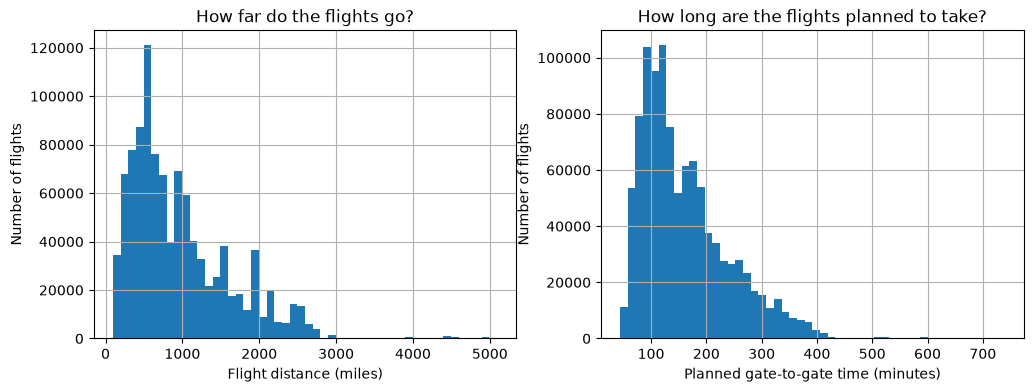

ARR_DEL15
0.0    0.802
1.0    0.198
Name: proportion, dtype: float64


In [5]:
# CRS = the airline's schedule (the plan). It is known before the flight leaves
# CRS_ELAPSED_TIME = planned time from gate to gate, taxi time included

display(df[["DISTANCE", "CRS_ELAPSED_TIME"]].describe().round(0))

# histograms of flight distance and planned gate-to-gate time, side by side
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
df["DISTANCE"].hist(bins=50, ax=axes[0])
axes[0].set(title="How far do the flights go?",
            xlabel="Flight distance (miles)", ylabel="Number of flights")
df["CRS_ELAPSED_TIME"].hist(bins=50, ax=axes[1])
axes[1].set(title="How long are the flights planned to take?",
            xlabel="Planned gate-to-gate time (minutes)", ylabel="Number of flights")
plt.show()

# share of on-time (0) and late (1) flights (value_counts skips empty cells by itself)
print(df["ARR_DEL15"].value_counts(normalize=True).round(3))

**Findings – Step 2:**
- **The values look realistic.** Distance goes from 95 to 5,095 miles, and the planned gate-to-gate time goes from 44 to 739 minutes. There are no zeros or negative values.
- **The times are stored as hhmm.** For example, 1430 means 14:30. This is not an error, but it is a problem for a model. 15:59 is stored as 1559 and 16:00 as 1600, so they look 41 apart, even though only one minute has passed. We fix this in Section 4.
- **Most flights are on time.** 80.2% are on time and 19.8% are late. Because of this, accuracy alone is not enough: a model that always says "on time" would already be 80% correct. We therefore also look at precision, recall and F1.

**Step 3 (Check 2): Do the columns make sense together? (Bivariate and multivariate analysis)**

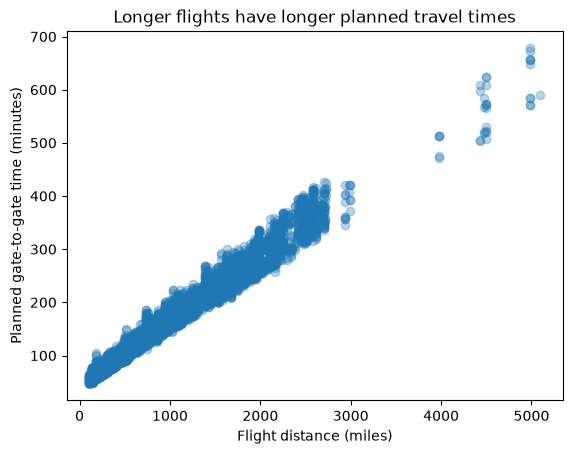

Correlation: 0.98
Strange flights: 0


In [6]:
# 10,000 random flights
sample = df.sample(10000, random_state=1)
plt.scatter(sample["DISTANCE"], sample["CRS_ELAPSED_TIME"], alpha=0.3)
plt.xlabel("Flight distance (miles)")
plt.ylabel("Planned gate-to-gate time (minutes)")
plt.title("Longer flights have longer planned travel times")
plt.show()

# correlation: 1 = perfect, 0 = no connection
print("Correlation:", round(df["DISTANCE"].corr(df["CRS_ELAPSED_TIME"]), 2))

# strange flights: over 1,500 miles but under 60 minutes (0 = none)
strange = df[(df["DISTANCE"] > 1500) & (df["CRS_ELAPSED_TIME"] < 60)]
print("Strange flights:", len(strange))

**Findings – Step 3:**
- Distance and planned gate-to-gate time go together: the longer the distance, the longer the planned time. The correlation is 0.98, so the two columns tell almost the same thing.
- We found no strange flights, such as a long distance with a very short planned time.

**Step 4 (Check 3): Does the data follow the rules? (Constraint and rule checking)**

In [7]:
# True = all flights follow the rule, False = some flights break it
# % 100 gives the last two digits of the time (the minutes)
rules = {
    "ARR_DEL15 is only 0 or 1": df["ARR_DEL15"].dropna().isin([0, 1]).all(),
    "CANCELLED is only 0 or 1": df["CANCELLED"].isin([0, 1]).all(),
    "DIVERTED is only 0 or 1": df["DIVERTED"].isin([0, 1]).all(),
    "All flights are from 2025": (df["FL_DATE"].dt.year == 2025).all(),
    "CRS_DEP_TIME is 0-2359": df["CRS_DEP_TIME"].between(0, 2359).all(),
    "CRS_DEP_TIME minutes < 60": (df["CRS_DEP_TIME"] % 100 < 60).all(),
    "CRS_ARR_TIME is 0-2359": df["CRS_ARR_TIME"].between(0, 2359).all(),
    "CRS_ARR_TIME minutes < 60": (df["CRS_ARR_TIME"] % 100 < 60).all(),
    "DISTANCE is above 0": (df["DISTANCE"] > 0).all(),
    "CRS_ELAPSED_TIME is above 0": (df["CRS_ELAPSED_TIME"] > 0).all(),
    "ORIGIN and DEST are different": (df["ORIGIN"] != df["DEST"]).all(),
    "No duplicate rows": not df.duplicated().any(),
}

for rule, ok in rules.items():
    print(ok, "-", rule)

True - ARR_DEL15 is only 0 or 1
True - CANCELLED is only 0 or 1
True - DIVERTED is only 0 or 1
True - All flights are from 2025
True - CRS_DEP_TIME is 0-2359
True - CRS_DEP_TIME minutes < 60
True - CRS_ARR_TIME is 0-2359
True - CRS_ARR_TIME minutes < 60
True - DISTANCE is above 0
True - CRS_ELAPSED_TIME is above 0
True - ORIGIN and DEST are different
True - No duplicate rows


**Findings – Step 4:**
We checked the rules that must always be true, for example:
- yes/no columns are only 0 or 1
- times are real clock times (00:00–23:59)
- distance and planned time are above 0
- a flight does not land at the same airport it left from
- no flight appears twice

All rules are **True**, so we found **no impossible values**.

We did not check that the arrival time is later than the departure time, because this is not true for many normal flights:
1. **Night flights** land after midnight. For example, a flight from Salt Lake City (SLC) to Atlanta (ATL) leaves at 23:35 and lands at 05:18.
2. **The times are local times.** A flight from Atlanta (ATL) to Los Angeles (LAX) leaves at 07:00 and lands at 08:33, but it is planned to take 273 minutes, because Los Angeles is 3 hours behind Atlanta.

The real planned travel time is in CRS_ELAPSED_TIME.

**Step 5 (Check 4): What is missing, and why? (Missingness analysis)**

In [8]:
# number of empty cells in each column
print(df.isna().sum())
print()

# are the flights with an empty target cancelled or diverted?
missing = df[df["ARR_DEL15"].isna()]
print("Flights with empty target:", len(missing))
print("Of these, cancelled:", int(missing["CANCELLED"].sum()))
print("Of these, diverted:", int(missing["DIVERTED"].sum()))

# share of flights with an empty target for each month (0.03 = 3%)
print()
print("Share of empty targets per month:")
print(df["ARR_DEL15"].isna().groupby(df["FL_DATE"].dt.month).mean().round(3))

FL_DATE                  0
OP_UNIQUE_CARRIER        0
ORIGIN                   0
DEST                     0
CRS_DEP_TIME             0
CRS_ARR_TIME             0
ARR_DEL15            13905
CANCELLED                0
DIVERTED                 0
CRS_ELAPSED_TIME         0
DISTANCE                 0
dtype: int64

Flights with empty target: 13905
Of these, cancelled: 11114
Of these, diverted: 2791

Share of empty targets per month:
FL_DATE
1     0.030
2     0.004
3     0.007
4     0.007
5     0.005
6     0.022
7     0.019
8     0.011
9     0.003
10    0.005
11    0.019
12    0.030
Name: ARR_DEL15, dtype: float64


**Findings – Step 5:**
- **How much is missing?** Only the target ARR_DEL15 is missing, for 13,905 flights (1.4%).
- **Which flights?** All of them were cancelled (11,114) or diverted (2,791). Missing target values are most common in January and December (3%).
- **Which type?** The missingness is systematic and can be explained by observed variables. Although this resembles MAR (Missing At Random), it is more appropriately described as structural missingness, because arrival delay at the scheduled destination is not meaningfully defined for these flights.
- **What we do:** We remove these flights in Section 4 rather than imputing artificial target values.
- **What it means for our results:** Our model predicts arrival delays conditional on flights being completed. It does not predict cancellations or diversions, which are unknown at the time of prediction.

**Summary – the 7 data quality dimensions**

| Dimension | What it asks | Our answer |
|---|---|---|
| Accuracy | Are the values correct? | Yes. The data comes from BTS, and all values look realistic (Check 1). |
| Completeness | Is anything missing? | Only the target, for 1.4% of the flights (Check 4). |
| Consistency | Is everything written the same way? | Yes. For example, all times are written as hhmm (Check 1). |
| Timeliness | Is the data recent enough? | Yes. 2025 is the newest full year. |
| Validity | Does the data follow the rules? | Yes. All rules are True, and there are no duplicates (Check 3). |
| Relevance | Does the data fit our question? | Yes. We only use information that is known before the flight leaves, plus the target. |
| Representativeness | Does the data show the full picture? | Mostly. The dataset covers Delta-operated domestic flights throughout 2025. However, excluding cancelled and diverted flights may underrepresent periods of severe operational disruption and limits the modelling population to completed flights. |

**Conclusion:** The data is in good shape. We found two things to fix in Section 4: the missing target for cancelled and diverted flights, and the hhmm format of the times.

## 4. Data wrangling

**The plan:**
1. Step 1 – Remove the flights without a target
2. Step 2 – Make new features from the date and the times
3. Step 3 – Turn the airports into 0/1 columns
4. Step 4 – Check the data again

**Note on the date:** FL_DATE was already turned into a real date in Section 2, when we loaded the data. We did it there because the checks in Section 3 needed to read the date, for example to check that all flights are from 2025. This only changes the format, not the values: pandas can now read the text as a date.

**Step 1: Remove the flights without a target**

In [9]:

# Keep only completed flights with a valid target
valid_status = (
    (df["CANCELLED"] == 0) &
    (df["DIVERTED"] == 0)
)

valid_target = df["ARR_DEL15"].isin([0, 1])

clean = df.loc[valid_status & valid_target].copy()

# Store the binary target as an integer
clean["ARR_DEL15"] = clean["ARR_DEL15"].astype(int)

print("Before:", len(df), "flights")
print("After:", len(clean), "flights")
print("Removed:", len(df) - len(clean), "flights")

Before: 1026332 flights
After: 1012427 flights
Removed: 13905 flights


**Findings – Step 1:**
We removed 13,905 cancelled or diverted flights without a valid arrival delay outcome. The final modelling population consists of 1,012,427 completed Delta flights.

This defines the scope of our model: predicting arrival delay risk for completed flights rather than predicting overall operational disruption. The original table df remains unchanged.

**Step 2: Make new features from the date and the times**

In [10]:
# month (1 = January, 12 = December) and weekday (1 = Monday, 7 = Sunday) from the date
clean["MONTH"] = clean["FL_DATE"].dt.month
clean["DAY_OF_WEEK"] = clean["FL_DATE"].dt.dayofweek + 1

# scheduled departure and arrival as minutes after midnight
# // 100 gives the hours and % 100 gives the minutes: 1430 -> 14 * 60 + 30 = 870
clean["DEP_MINUTES"] = (clean["CRS_DEP_TIME"] // 100) * 60 + clean["CRS_DEP_TIME"] % 100
clean["ARR_MINUTES"] = (clean["CRS_ARR_TIME"] // 100) * 60 + clean["CRS_ARR_TIME"] % 100

# show 5 flights, to check that the new columns look right
display(clean[["FL_DATE", "MONTH", "DAY_OF_WEEK", "CRS_DEP_TIME", "DEP_MINUTES", "CRS_ARR_TIME", "ARR_MINUTES"]].head())

,FL_DATE,MONTH,DAY_OF_WEEK,CRS_DEP_TIME,DEP_MINUTES,CRS_ARR_TIME,ARR_MINUTES
0,2025-01-01,1,3,635,395,1132,692
1,2025-01-01,1,3,1135,695,1633,993
2,2025-01-01,1,3,800,480,1139,699
3,2025-01-01,1,3,605,365,859,539
4,2025-01-01,1,3,1413,853,1705,1025


**Findings – Step 2:** We made four new features:
- **MONTH** and **DAY_OF_WEEK** from the date, to capture seasons and weekdays.
- **DEP_MINUTES** and **ARR_MINUTES** from the scheduled times, as minutes after midnight. Now 15:59 is 959 and 16:00 is 960, so they are exactly one minute apart, just like in real life.

**Step 3: Turn the airports into 0/1 columns**

ORIGIN and DEST are categorical attributes without a natural order. As in Lecture 4 (ocean view: No = 0, Yes = 1), we turn them into binary 0/1 attributes: one attribute per airport, with 1 if the flight uses that airport and 0 if not.

In [11]:
# as in Exercise 03, Task 3, we use pd.get_dummies(): it makes one column per airport,
# e.g. ORIGIN_ATL = 1 if the flight leaves from Atlanta, else 0
# dtype="int8" gives 0/1 instead of True/False, and uses little memory
airports = pd.get_dummies(clean[["ORIGIN", "DEST"]], dtype="int8")

# add the new columns to clean. ORIGIN and DEST stay as text too,
# so we can still use them to look at the data, e.g. delays per airport
clean = pd.concat([clean, airports], axis=1)

# lists of the new column names, so we can use them as features in Section 5
origin_cols = [col for col in airports.columns if col.startswith("ORIGIN_")]
dest_cols = [col for col in airports.columns if col.startswith("DEST_")]
print("Number of ORIGIN columns:", len(origin_cols))
print("Number of DEST columns:", len(dest_cols))

# show 5 flights: the airport as text, and a few of the new 0/1 columns
clean[["ORIGIN", "DEST", "ORIGIN_ATL", "ORIGIN_JFK", "ORIGIN_LAX", "DEST_ATL", "DEST_JFK", "DEST_LAX"]].head()

Number of ORIGIN columns: 153
Number of DEST columns: 153


,ORIGIN,DEST,ORIGIN_ATL,ORIGIN_JFK,ORIGIN_LAX,DEST_ATL,DEST_JFK,DEST_LAX
0,ABQ,ATL,0,0,0,1,0,0
1,ABQ,ATL,0,0,0,1,0,0
2,ABQ,MSP,0,0,0,0,0,0
3,ALB,ATL,0,0,0,1,0,0
4,ALB,ATL,0,0,0,1,0,0


**Findings – Step 3:** We got 306 new 0/1 columns: 153 for ORIGIN and 153 for DEST. We added them to `clean`, and we also kept ORIGIN and DEST as text, so we can still see the airport names.

This step does not learn anything from the data. It only gives each airport its own column. So it is fine to do it before the train/test split.

**Step 4: Check the data again**

In [12]:
# size, empty cells and the target after all the changes
print("Rows and columns:", clean.shape)
print("Empty cells in total:", clean.isna().sum().sum())
print(clean["ARR_DEL15"].value_counts(normalize=True).round(3))

# check that the new columns only have possible values
print("MONTH is 1-12:", clean["MONTH"].between(1, 12).all())
print("DAY_OF_WEEK is 1-7:", clean["DAY_OF_WEEK"].between(1, 7).all())
print("DEP_MINUTES is 0-1439:", clean["DEP_MINUTES"].between(0, 1439).all())
print("ARR_MINUTES is 0-1439:", clean["ARR_MINUTES"].between(0, 1439).all())

# each flight leaves from exactly one airport and lands at exactly one airport,
# so the ORIGIN columns must add up to 1 in every row, and the same for the DEST columns
print("Exactly one ORIGIN airport per flight:", (clean[origin_cols].sum(axis=1) == 1).all())
print("Exactly one DEST airport per flight:", (clean[dest_cols].sum(axis=1) == 1).all())


# after removing the flights without a target, no flights should be cancelled or diverted
print("CANCELLED and DIVERTED are all 0:", (clean[["CANCELLED", "DIVERTED"]] == 0).all().all())

# number of flights and share of delayed flights for each departure hour (0.08 = 8%)
# // 60 groups the minutes into whole hours, only to make the table short enough to read
dep_hour = (clean["DEP_MINUTES"] // 60).rename("DEP_HOUR")
display(clean.groupby(dep_hour)["ARR_DEL15"].agg(flights="size", delay_rate="mean").round(2))

Rows and columns: (1012427, 321)
Empty cells in total: 0
ARR_DEL15
0    0.802
1    0.198
Name: proportion, dtype: float64
MONTH is 1-12: True
DAY_OF_WEEK is 1-7: True
DEP_MINUTES is 0-1439: True
ARR_MINUTES is 0-1439: True
Exactly one ORIGIN airport per flight: True
Exactly one DEST airport per flight: True
CANCELLED and DIVERTED are all 0: True


,flights,delay_rate
DEP_HOUR,,
0,2155,0.14
1,505,0.17
3,16,0.25
5,25969,0.08
6,69797,0.09
7,87951,0.12
8,64760,0.13
9,53385,0.15
10,56201,0.16


**Findings – Step 4:**
- **Size:** `clean` has 1,012,427 flights and 321 columns: 11 original columns, 4 time features and 306 airport columns.
- **Empty cells:** There are none.
- **Target:** Still 80.2% on time and 19.8% late, so removing the cancelled and diverted flights did not change the balance.
- **New columns:** All values are possible, and every flight has exactly one ORIGIN airport and one DEST airport (all True).
- **Delays by hour:** Late flights become more common during the day, from 8% at 5 am to 31% at 7 pm, and then drop to 22% late in the evening. So the departure time matters for delays. There are no flights at 2 am and 4 am.
- **Columns we will not use as features:** FL_DATE, CRS_DEP_TIME, CRS_ARR_TIME, ORIGIN and DEST, because we made new features from them. OP_UNIQUE_CARRIER (always DL), CANCELLED and DIVERTED (always 0), because they are the same for every flight.

## 5. Preparing the data for the models

We follow the same steps as in Exercise 03 (decision trees):
1. Step 1 – Choose the features (X) and the target (y)
2. Step 2 – Split the flights into a training set and a test set
3. Step 3 – Scale the numeric features

**Step 1: Choose the features (X) and the target (y)**

In [13]:
# the numeric features: only information that is known before the flight leaves
NUMERIC_FEATURES = [
    "MONTH", "DAY_OF_WEEK",           # from the date
    "DEP_MINUTES", "ARR_MINUTES",     # scheduled times, as minutes after midnight
    "CRS_ELAPSED_TIME", "DISTANCE",   # planned gate-to-gate time and distance
]

# all features = the numeric features + the 0/1 airport columns from Section 4
FEATURES = NUMERIC_FEATURES + origin_cols + dest_cols

# X = the features, y = the target (1 = at least 15 minutes late, 0 = on time)
X = clean[FEATURES]
y = clean["ARR_DEL15"]

print("X:", X.shape)
print("y:", y.shape)

# check that X has no text or date columns (a model can only use numbers)
print("All features are numbers:", X.dtypes.apply(pd.api.types.is_numeric_dtype).all())
X.head()

X: (1012427, 312)
y: (1012427,)
All features are numbers: True


,MONTH,DAY_OF_WEEK,DEP_MINUTES,ARR_MINUTES,CRS_ELAPSED_TIME,DISTANCE,ORIGIN_ABQ,ORIGIN_AGS,ORIGIN_ALB,ORIGIN_ANC,...,DEST_SYR,DEST_TLH,DEST_TPA,DEST_TRI,DEST_TUL,DEST_TUS,DEST_TVC,DEST_TYS,DEST_VPS,DEST_XNA
0,1,3,395,692,177.0,1269.0,1,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,1,3,695,993,178.0,1269.0,1,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,1,3,480,699,159.0,981.0,1,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,1,3,365,539,174.0,853.0,0,0,1,0,...,0,0,0,0,0,0,0,0,0,0
4,1,3,853,1025,172.0,853.0,0,0,1,0,...,0,0,0,0,0,0,0,0,0,0


**Findings – Step 1:** X has 312 features: 6 numeric features and 306 airport columns. All features are numbers and are known before the flight leaves. y is the target, ARR_DEL15.

DISTANCE and CRS_ELAPSED_TIME are almost the same (correlation 0.98, see Check 2). We keep both for now.

**Step 2: Split the flights into a training set and a test set**

In [14]:

from sklearn.model_selection import train_test_split

# 95% for training and 5% for testing
# Given our large dataset, 5% still provides a substantial
# test set for final model evaluation.
# Stratification preserves the target distribution.

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.05, random_state=42, stratify=y
)

# Check the sizes of the two datasets
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

# Check the proportion of delayed flights
print("Share of late flights in training set:",
      round(y_train.mean(), 3))

print("Share of late flights in test set:",
      round(y_test.mean(), 3))

X_train: (961805, 312)
X_test: (50622, 312)
Share of late flights in training set: 0.198
Share of late flights in test set: 0.198


**Findings – Step 2:**
Training set: 961,805 flights (95%).

Test set: 50,622 flights (5%).

Class distribution: By using stratify=y, approximately 19.8% of the flights are delayed in both sets.

Choice of split: Given our large dataset of over one million observations, we use a 95/5 split rather than the conventional 70/30 split. This allows us to retain more observations for model training while maintaining a substantial test set for final evaluation (Ng, 2018; Pargent et al., 2023).

Limitation: The split is random, so flights from the same day may appear in both sets. Shared operational conditions may therefore result in optimistic estimates of performance on future periods.

Validation: Model selection and hyperparameter tuning will be conducted using 3-fold stratified cross-validation within the training set. The test set is reserved for final evaluation.


**Step 3: Scale the numeric features**

In [15]:
from sklearn.preprocessing import StandardScaler

# the numeric features have very different scales, e.g. DAY_OF_WEEK goes from 1 to 7
# and DISTANCE goes up to 5,095. Scaling gives them all mean 0 and standard deviation 1.
# the 0/1 airport columns are not scaled.
scaler = StandardScaler()

# fit the scaler on the training set ONLY, so it learns nothing from the test set
scaler.fit(X_train[NUMERIC_FEATURES])

# use the same scaler on both sets (copies, so X_train and X_test stay unscaled)
X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()
X_train_scaled[NUMERIC_FEATURES] = scaler.transform(X_train[NUMERIC_FEATURES])
X_test_scaled[NUMERIC_FEATURES] = scaler.transform(X_test[NUMERIC_FEATURES])

# check: in the training set the numeric features now have mean 0 and standard deviation 1
X_train_scaled[NUMERIC_FEATURES].describe().loc[["mean", "std"]].round(2)

,MONTH,DAY_OF_WEEK,DEP_MINUTES,ARR_MINUTES,CRS_ELAPSED_TIME,DISTANCE
mean,0.0,-0.0,-0.0,-0.0,-0.0,0.0
std,1.0,1.0,1.0,1.0,1.0,1.0


**Findings – Step 3:** The 6 numeric features in the training set now have mean 0 and standard deviation 1. We only scaled them, not the 0/1 airport columns. We fitted the scaler on the training set only, so the test set does not affect it.

We now have two versions of the data: `X_train` / `X_test` (not scaled) and `X_train_scaled` / `X_test_scaled` (scaled).

## 6. Exploratory Data Analysis – Delay patterns

In Section 3, we examined the quality of our data. In this section, we investigate patterns in flight delays that are relevant to our machine learning question.

**The plan:**

1. Delay rate by month
2. Delay rate by day of week
3. Delay rate by scheduled departure hour
4. Delay rate by origin and destination airport
5. Interaction between month and departure hour

The purpose is to identify potentially informative predictors and explore relationships that our machine learning models may be able to capture.

We conduct these analyses using the training set only to avoid using test data for modelling decisions. The identified patterns represent associations rather than causal relationships.

In [16]:
# Use training data only for EDA
eda = clean.loc[X_train.index, [
    "MONTH", "DAY_OF_WEEK", "DEP_MINUTES",
    "ORIGIN", "DEST", "ARR_DEL15"
]].copy()

# Create departure hour for visualisation
eda["DEP_HOUR"] = eda["DEP_MINUTES"] // 60

# Calculate overall delay rate
overall_delay = eda["ARR_DEL15"].mean() * 100

print("Number of flights:", len(eda))
print("Overall delay rate:", round(overall_delay, 2), "%")

Number of flights: 961805
Overall delay rate: 19.79 %


### 6.1 Delay rate by month

**What we do:** We compare the proportion of delayed flights across the twelve months of 2025.

**Why:** Delay risk may vary throughout the year. This analysis helps us investigate whether MONTH is a potentially useful predictor.

,flights,delay_rate,delay_rate_pct
MONTH,,,
1,70338,0.19,19.36
2,67420,0.20,19.92
3,79744,0.18,18.45
4,79366,0.18,17.76
5,84880,0.22,22.02
6,84832,0.26,26.13
7,87674,0.25,24.86
8,84805,0.17,17.05
9,80464,0.12,12.42


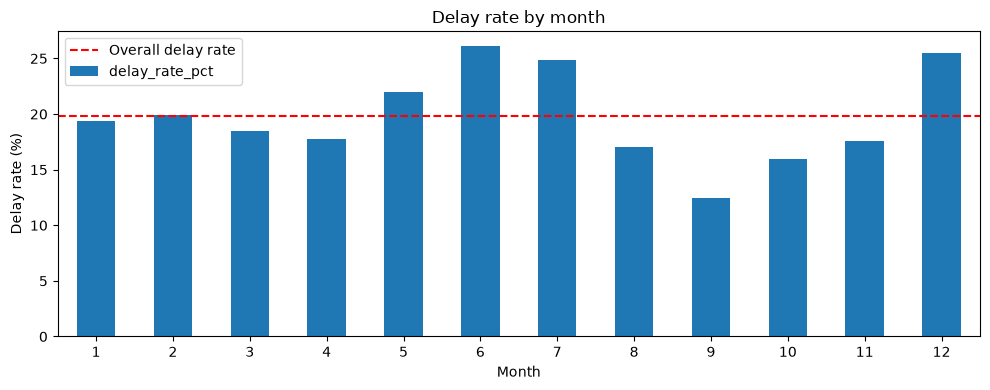

Highest delay rate: 6
Delay rate (%): 26.13
Lowest delay rate: 9
Delay rate (%): 12.42


In [17]:
monthly = eda.groupby("MONTH")["ARR_DEL15"].agg(
    flights="size",
    delay_rate="mean"
)

monthly["delay_rate_pct"] = monthly["delay_rate"] * 100

display(monthly.round(2))

monthly["delay_rate_pct"].plot(
    kind="bar", figsize=(10, 4)
)

plt.axhline(
    overall_delay, color="red",
    linestyle="--", label="Overall delay rate"
)

plt.title("Delay rate by month")
plt.xlabel("Month")
plt.ylabel("Delay rate (%)")
plt.xticks(rotation=0)
plt.legend()
plt.tight_layout()
plt.show()

print("Highest delay rate:", monthly["delay_rate_pct"].idxmax())
print("Delay rate (%):", round(monthly["delay_rate_pct"].max(), 2))

print("Lowest delay rate:", monthly["delay_rate_pct"].idxmin())
print("Delay rate (%):", round(monthly["delay_rate_pct"].min(), 2))

**Findings – 6.1:**

- The highest delay rate was observed in June (26.13%).
- The lowest delay rate was observed in September (12.42%).
- Delay rates are also high in July (24.86%) and December (25.50%), while August–November sit at or below the overall rate of 19.79%.
- Differences in delay rates across months suggest that MONTH may be a useful predictor.
- However, since we only have data from 2025, we cannot determine whether these patterns repeat every year.

### 6.2 Delay rate by day of week

**What we do:** We compare the proportion of delayed flights across the seven days of the week.

**Why:** Flight demand and operational conditions may differ between weekdays and weekends. This analysis helps us investigate whether DAY_OF_WEEK is a potentially useful predictor.

,flights,delay_rate,delay_rate_pct
DAY_OF_WEEK,,,
Monday,143262,0.21,21.43
Tuesday,136021,0.17,16.62
Wednesday,137532,0.16,16.14
Thursday,141928,0.20,19.83
Friday,140947,0.20,20.39
Saturday,121610,0.19,19.21
Sunday,140505,0.25,24.64


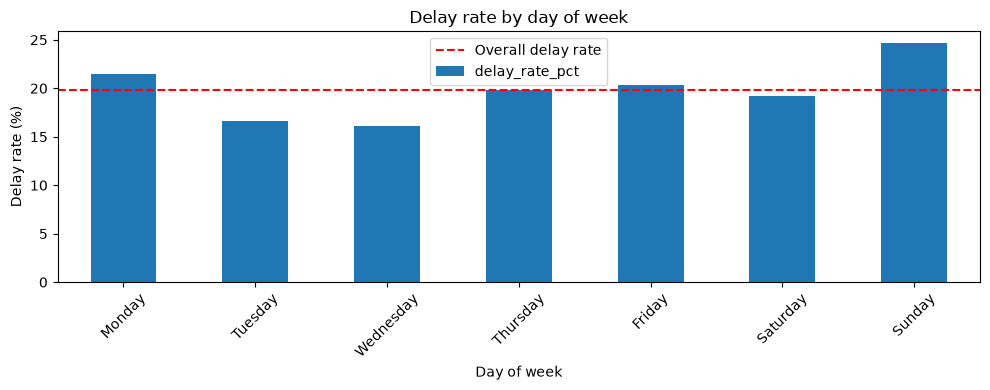

Highest delay rate: Sunday
Lowest delay rate: Wednesday


In [18]:
weekday = eda.groupby("DAY_OF_WEEK")["ARR_DEL15"].agg(
    flights="size",
    delay_rate="mean"
)

weekday["delay_rate_pct"] = weekday["delay_rate"] * 100

weekday = weekday.rename(index={
    1: "Monday",
    2: "Tuesday",
    3: "Wednesday",
    4: "Thursday",
    5: "Friday",
    6: "Saturday",
    7: "Sunday"
})

display(weekday.round(2))

weekday["delay_rate_pct"].plot(
    kind="bar", figsize=(10, 4)
)

plt.axhline(
    overall_delay, color="red",
    linestyle="--", label="Overall delay rate"
)

plt.title("Delay rate by day of week")
plt.xlabel("Day of week")
plt.ylabel("Delay rate (%)")
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.show()

print("Highest delay rate:", weekday["delay_rate_pct"].idxmax())
print("Lowest delay rate:", weekday["delay_rate_pct"].idxmin())

**Findings – 6.2:**

- The highest delay rate was observed on Sunday (24.64%).
- The lowest delay rate was observed on Wednesday (16.14%).
- Monday (21.43%) and Friday (20.39%) are also above the overall rate, while Tuesday and Wednesday are clearly below it.
- Delay risk therefore varies across the week, which suggests that DAY_OF_WEEK may contribute to predictive performance.

### 6.3 Delay rate by scheduled departure hour

**What we do:** We compare delay rates across scheduled departure hours.

**Why:** Operational disruptions may accumulate throughout the day. We investigate whether flights scheduled later in the day are associated with a higher probability of arriving late.

,flights,delay_rate,delay_rate_pct
DEP_HOUR,,,
0,2051,0.14,13.94
1,483,0.18,17.60
3,16,0.25,25.00
5,24608,0.08,8.05
6,66316,0.09,9.25
7,83517,0.12,12.07
8,61556,0.13,13.50
9,50733,0.15,14.59
10,53458,0.16,15.73


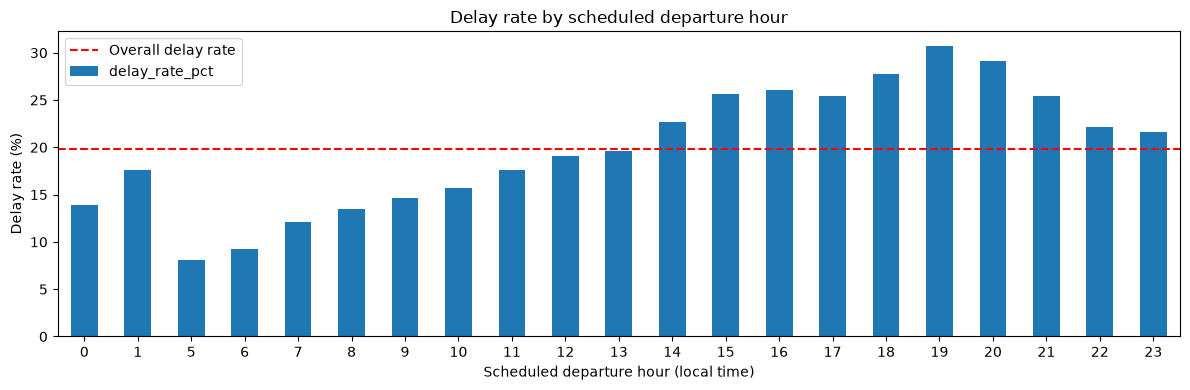

Highest delay rate: 19
Lowest delay rate: 5


In [19]:
hourly = eda.groupby("DEP_HOUR")["ARR_DEL15"].agg(
    flights="size",
    delay_rate="mean"
)

hourly["delay_rate_pct"] = hourly["delay_rate"] * 100

display(hourly.round(2))

# Only visualise hours with at least 100 flights
hourly_plot = hourly[hourly["flights"] >= 100]

hourly_plot["delay_rate_pct"].plot(
    kind="bar", figsize=(12, 4)
)

plt.axhline(
    overall_delay, color="red",
    linestyle="--", label="Overall delay rate"
)

plt.title("Delay rate by scheduled departure hour")
plt.xlabel("Scheduled departure hour (local time)")
plt.ylabel("Delay rate (%)")
plt.xticks(rotation=0)
plt.legend()
plt.tight_layout()
plt.show()

print("Highest delay rate:", hourly_plot["delay_rate_pct"].idxmax())
print("Lowest delay rate:", hourly_plot["delay_rate_pct"].idxmin())

**Findings – 6.3:**

- Among hours with at least 100 flights, the highest delay rate was observed at 19:00 (30.72%).
- The lowest delay rate was observed at 05:00 (8.05%).
- Delay risk rises steadily through the day: morning departures (05:00–09:00) stay well below the overall rate, while afternoon and evening departures (from about 14:00) are clearly above it.
- This pattern suggests that scheduled departure time (DEP_MINUTES) is likely a useful predictor.

### 6.4 Delay rate by origin and destination airport

**What we do:** We compare delay rates across origin and destination airports.

**Why:** Airports may differ in terms of congestion, traffic volume and operational conditions. We investigate whether airport characteristics are associated with different levels of delay risk.

To avoid overinterpreting airports with very few observations, we only visualise airports with at least 1,000 flights in the training data.

Highest delay rates by ORIGIN


,flights,delay_rate,delay_rate_pct
ORIGIN,,,
EWR,6080,0.29,29.14
MIA,10422,0.27,27.11
LGA,27053,0.27,27.09
ORD,10353,0.26,25.94
BOS,24165,0.24,24.33
MCO,19534,0.24,23.86
FLL,11775,0.24,23.78
PBI,6670,0.23,23.48
ATL,221827,0.23,23.08


Lowest delay rates by ORIGIN


,flights,delay_rate,delay_rate_pct
ORIGIN,,,
ONT,1695,0.08,8.32
SJC,2316,0.09,8.85
TUS,1044,0.09,9.20
SMF,3280,0.10,9.57
MSN,1642,0.10,9.93
PNS,2607,0.10,10.43
ABQ,1099,0.10,10.46
PDX,6847,0.11,10.90
GSP,2769,0.11,11.20


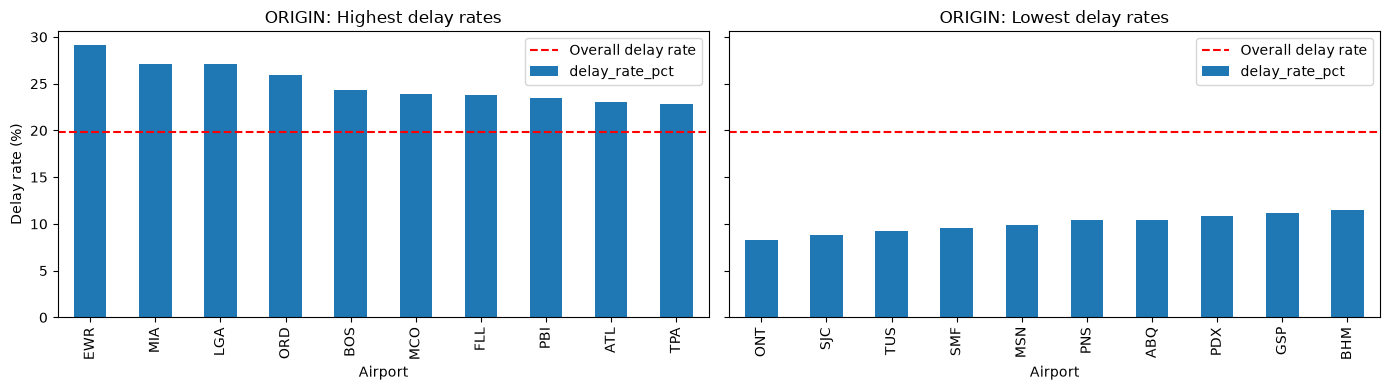

Highest delay rates by DEST


,flights,delay_rate,delay_rate_pct
DEST,,,
EWR,6033,0.35,34.81
DCA,8622,0.30,29.54
ORD,10310,0.28,28.50
PBI,6753,0.28,28.36
PVD,1156,0.28,28.03
MIA,10495,0.28,27.69
ALB,1209,0.28,27.54
DFW,11228,0.27,27.29
DEN,10850,0.27,27.20


Lowest delay rates by DEST


,flights,delay_rate,delay_rate_pct
DEST,,,
OGG,1121,0.14,13.74
SLC,51530,0.15,15.20
SEA,30125,0.16,16.06
ATL,221758,0.16,16.39
DAY,1295,0.17,16.53
IND,4135,0.17,16.57
ICT,1050,0.17,16.86
VPS,2473,0.17,17.02
DAB,1477,0.17,17.06


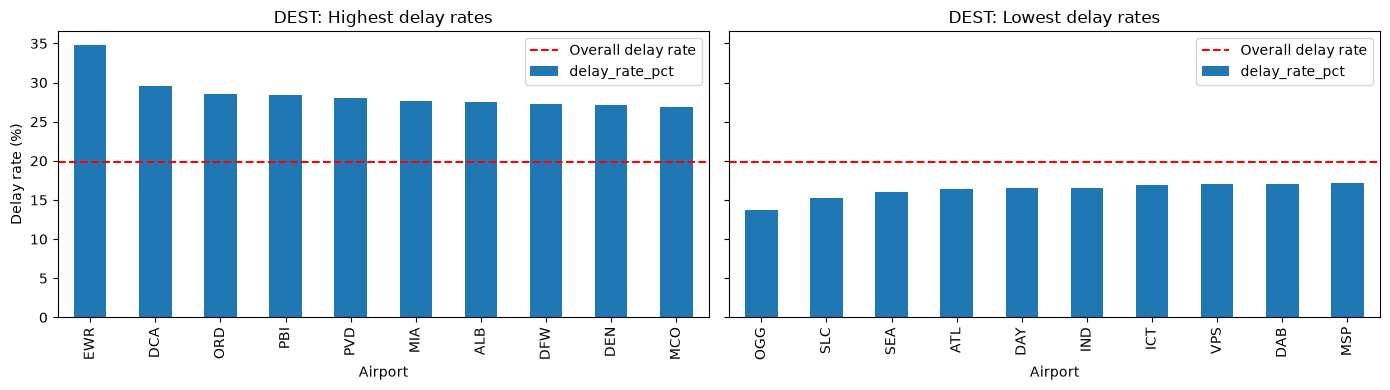

In [20]:
for airport in ["ORIGIN", "DEST"]:

    airport_summary = eda.groupby(airport)["ARR_DEL15"].agg(
        flights="size",
        delay_rate="mean"
    )

    airport_summary = airport_summary[
        airport_summary["flights"] >= 1000
    ].copy()

    airport_summary["delay_rate_pct"] = (
        airport_summary["delay_rate"] * 100
    )

    top_10 = airport_summary.nlargest(10, "delay_rate_pct")
    bottom_10 = airport_summary.nsmallest(10, "delay_rate_pct")

    print(f"Highest delay rates by {airport}")
    display(top_10.round(2))

    print(f"Lowest delay rates by {airport}")
    display(bottom_10.round(2))

    fig, axes = plt.subplots(
        1, 2, figsize=(14, 4), sharey=True
    )

    top_10["delay_rate_pct"].plot(
        kind="bar", ax=axes[0]
    )

    bottom_10["delay_rate_pct"].plot(
        kind="bar", ax=axes[1]
    )

    axes[0].set_title(f"{airport}: Highest delay rates")
    axes[1].set_title(f"{airport}: Lowest delay rates")

    for ax in axes:
        ax.axhline(
            overall_delay, color="red",
            linestyle="--", label="Overall delay rate"
        )
        ax.set_ylabel("Delay rate (%)")
        ax.set_xlabel("Airport")
        ax.legend()

    plt.tight_layout()
    plt.show()

**Findings – 6.4:**

- Among the origin airports with at least 1,000 observations, EWR has the highest delay rate (29.14%), while ONT has the lowest (8.32%).
- Among the destination airports, EWR has the highest delay rate (34.81%), while OGG has the lowest (13.74%).
- Other high-delay origins include MIA, LGA and ORD; other high-delay destinations include DCA, ORD and PBI.
- Differences between airports may indicate that ORIGIN and DEST contain useful predictive information.
- These differences should not be interpreted as causal effects, as airports may differ in other characteristics such as flight schedules, routes and weather conditions.

### 6.5 Interaction between month and departure hour

**What we do:** We create a heatmap showing delay rates for combinations of month and scheduled departure hour.

**Why:** The relationship between departure time and delay risk may differ across months. This analysis helps us investigate potential interactions between predictors, rather than examining each variable independently.

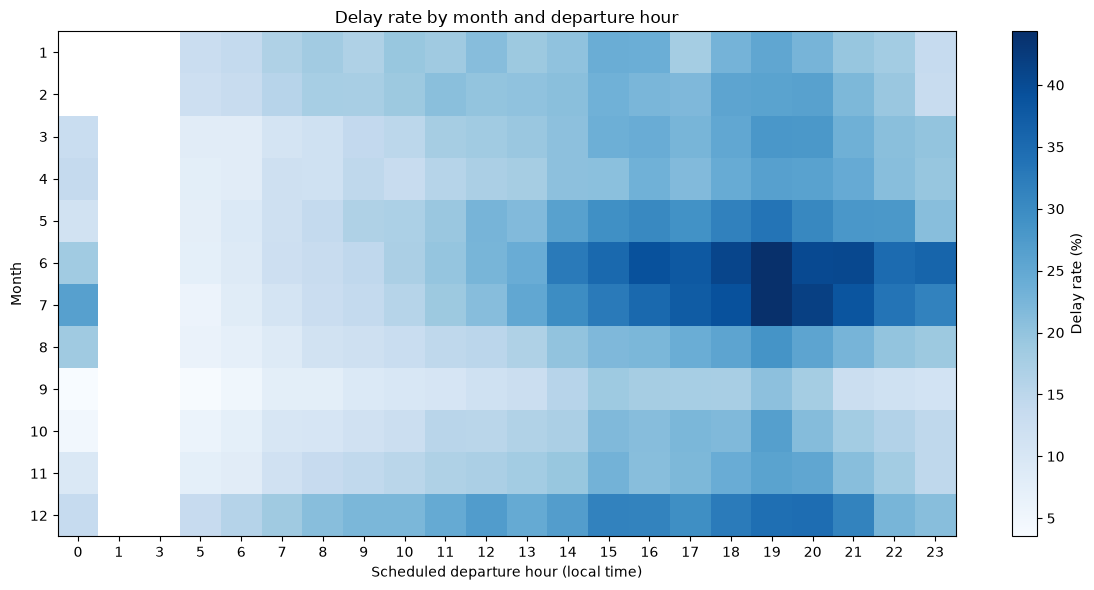

In [21]:
# Calculate the delay rate for each combination
delay_matrix = eda.pivot_table(
    index="MONTH",
    columns="DEP_HOUR",
    values="ARR_DEL15",
    aggfunc="mean"
) * 100

# Count flights in each combination
flight_counts = eda.pivot_table(
    index="MONTH",
    columns="DEP_HOUR",
    values="ARR_DEL15",
    aggfunc="size"
)

# Hide combinations with fewer than 100 flights
delay_matrix = delay_matrix.where(flight_counts >= 100)

plt.figure(figsize=(12, 6))

plt.imshow(
    delay_matrix, aspect="auto", cmap="Blues"
)

plt.colorbar(label="Delay rate (%)")

plt.xticks(
    range(len(delay_matrix.columns)),
    delay_matrix.columns
)

plt.yticks(
    range(len(delay_matrix.index)),
    delay_matrix.index
)

plt.xlabel("Scheduled departure hour (local time)")
plt.ylabel("Month")
plt.title("Delay rate by month and departure hour")

plt.tight_layout()
plt.show()

**Findings – 6.5:**

- Across months, delay rates are generally lowest in the early morning and rise towards the late afternoon and evening.
- The daily pattern is not the same in every month: evening delay rates are especially high in June, July and December (often above 30–40%), while September and October stay comparatively low even later in the day.
- Because the relationship between departure hour and delay risk differs across months, this suggests a potential interaction between MONTH and DEP_MINUTES.
- Such interactions motivate the use of tree-based models, which can capture complex relationships between predictors without explicitly specifying interaction terms.

### 6.6 Summary of EDA findings

The exploratory data analysis investigates how arrival delay risk varies across calendar months, weekdays, scheduled departure hours and airports. In the training data (961,805 flights from the 95/5 split), the overall delay rate is 19.79%.

- **Month:** Delay rates range from 12.42% in September to 26.13% in June, with July and December also high.
- **Day of week:** Sunday has the highest delay rate (24.64%) and Wednesday the lowest (16.14%).
- **Departure hour:** Delay risk rises through the day, from 8.05% at 05:00 to 30.72% at 19:00.
- **Airports:** Among airports with at least 1,000 flights, EWR has the highest delay rates as both origin (29.14%) and destination (34.81%); ONT and OGG have the lowest.
- **Interaction:** Evening delay risk is much stronger in June, July and December than in September–October, which points to a potential interaction between MONTH and DEP_MINUTES.

These patterns support keeping MONTH, DAY_OF_WEEK, DEP_MINUTES, ORIGIN and DEST as predictors. Potential non-linear relationships and interactions motivate the comparison of Logistic Regression, Decision Tree and Random Forest.

All analyses in this section are based on the training data. The identified relationships are descriptive associations and should not be interpreted as causal effects. Whether these predictors contribute to generalizable predictive performance will be investigated in the following modelling section.

## 7. Modelling

In the previous sections, we collected, explored and prepared the data for modelling. Our exploratory data analysis identified patterns in arrival delays across months, weekdays, scheduled departure hours and airports.

We now investigate whether supervised machine learning models can use these characteristics to predict whether a Delta-operated flight will arrive at least 15 minutes late.

**The plan:**

1. Modelling strategy and validation
2. Baseline – DummyClassifier
3. Logistic Regression
4. Decision Tree
5. Random Forest
6. Overfitting and model generalization
7. Hyperparameter tuning
8. Summary of selected models

We compare models with different levels of complexity to investigate whether more complex models provide better predictive performance than simpler alternatives.

All model selection and hyperparameter tuning are conducted using the training data. The test set is reserved for final model evaluation in Section 8.

### 7.1 Modelling strategy and validation

**What we do:** We establish a common training and validation strategy for all classification models.

**Why:** To ensure a fair comparison, all models are trained and validated using the same observations and evaluation metrics.

As established in Section 5, we use a 95/5 stratified train/test split. The training set contains 961,805 flights, while the test set contains 50,622 flights. Given the large dataset, this allocation allows us to maximize the amount of data available for model development while retaining a substantial independent holdout set for final evaluation.

We use 3-fold stratified cross-validation within the training set to estimate how well the models generalize to unseen observations. Stratification preserves the proportion of delayed and non-delayed flights across the folds.

**Evaluation metrics:**

- Accuracy: the proportion of correctly classified flights.
- Precision: the proportion of predicted delayed flights that are actually delayed.
- Recall: the proportion of actual delayed flights that are correctly identified.
- F1-score: the harmonic mean of precision and recall.
- ROC-AUC: the model's ability to distinguish between delayed and non-delayed flights across classification thresholds.

Due to the imbalanced target distribution, accuracy alone is insufficient. We use ROC-AUC as our primary metric for model selection, while precision, recall and F1-score help us understand the practical consequences of classification errors.

In [22]:
from sklearn.model_selection import (
    StratifiedKFold, cross_validate, GridSearchCV
)

from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.metrics import make_scorer, precision_score

# Use the same cross-validation strategy for all models
cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

# Evaluation metrics
scoring = {
    "accuracy": "accuracy",
    "precision": make_scorer(
        precision_score, zero_division=0
    ),
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc"
}

print("Number of CV folds:", cv.get_n_splits())
print("Training observations:", len(y_train))
print("Test observations:", len(y_test))

Number of CV folds: 3
Training observations: 961805
Test observations: 50622


In [23]:
# Use the eight predictors before encoding and scaling
CATEGORICAL_FEATURES = ["ORIGIN", "DEST"]

RAW_FEATURES = NUMERIC_FEATURES + CATEGORICAL_FEATURES

# Keep the existing 95/5 split
X_train_raw = clean.loc[X_train.index, RAW_FEATURES].copy()
X_test_raw = clean.loc[X_test.index, RAW_FEATURES].copy()

# Preprocessing for Logistic Regression
preprocessor_scaled = ColumnTransformer([
    ("numeric", StandardScaler(), NUMERIC_FEATURES),
    ("categorical",
     OneHotEncoder(handle_unknown="ignore"),
     CATEGORICAL_FEATURES)
])

# Preprocessing for Decision Tree and Random Forest
preprocessor_unscaled = ColumnTransformer([
    ("numeric", "passthrough", NUMERIC_FEATURES),
    ("categorical",
     OneHotEncoder(handle_unknown="ignore"),
     CATEGORICAL_FEATURES)
])

print("Training data:", X_train_raw.shape)
print("Test data:", X_test_raw.shape)

Training data: (961805, 8)
Test data: (50622, 8)


In [24]:
# Store validation results for each model
model_results = {}

# Common evaluation function
def evaluate_model(name, model, X_data, y_data):

    scores = cross_validate(
        model,
        X_data,
        y_data,
        cv=cv,
        scoring=scoring,
        return_train_score=True,
        n_jobs=1
    )

    results = {
        "Accuracy": scores["test_accuracy"].mean(),
        "Precision": scores["test_precision"].mean(),
        "Recall": scores["test_recall"].mean(),
        "F1": scores["test_f1"].mean(),
        "ROC-AUC": scores["test_roc_auc"].mean(),
        "ROC-AUC SD": scores["test_roc_auc"].std(),
        "Training ROC-AUC": scores["train_roc_auc"].mean()
    }

    # Difference between training and validation performance
    results["Generalization gap"] = (
        results["Training ROC-AUC"] - results["ROC-AUC"]
    )

    model_results[name] = results

    display(pd.DataFrame([results], index=[name]).round(4))

    return scores

### 7.2 Baseline – DummyClassifier

**What we do:** We establish a simple baseline using a DummyClassifier with the most_frequent strategy.

**Why:** We need a reference point to determine whether our machine learning models provide predictive value beyond a simple majority-class prediction.

The DummyClassifier always predicts the most frequent class without learning relationships between the predictors and the target.

Since approximately 80.2% of our flights are not delayed, we expect the baseline to achieve relatively high accuracy despite being unable to identify delayed flights.

This demonstrates why accuracy alone can be misleading when evaluating classification models on imbalanced data.

In [25]:
# Create a majority-class baseline
dummy_model = DummyClassifier(
    strategy="most_frequent"
)

# Evaluate using 3-fold cross-validation
dummy_scores = evaluate_model(
    "DummyClassifier",
    dummy_model,
    X_train_raw,
    y_train
)

,Accuracy,Precision,Recall,F1,ROC-AUC,ROC-AUC SD,Training ROC-AUC,Generalization gap
DummyClassifier,0.8021,0.0,0.0,0.0,0.5,0.0,0.5,0.0


**Findings – 7.2:**

- The DummyClassifier achieves an accuracy of approximately 80.2%, reflecting the proportion of non-delayed flights.
- The model does not identify any delayed flights, resulting in a recall and F1-score of 0. Precision is undefined because there are no positive predictions and is therefore reported as 0.
- The ROC-AUC is 0.50, meaning that the model cannot distinguish between delayed and non-delayed flights.
- Despite its high accuracy, the model provides no useful information for identifying flights at increased risk of delay.
- These results establish a baseline against which the remaining machine learning models can be evaluated.

### 7.3 Logistic Regression

**What we do:** We train a Logistic Regression model to estimate the probability that a flight arrives at least 15 minutes late.

**Why:** Logistic Regression is a relatively simple and interpretable parametric classification model. It allows us to investigate whether our selected predictors contain useful information about arrival delay risk.

The model transforms a linear combination of the predictors into a probability between 0 and 1 using the logistic function.

We standardize the numerical predictors and apply One-Hot Encoding to the categorical predictors within a Pipeline.

We first train a standard Logistic Regression model and subsequently investigate whether balanced class weights improve the identification of delayed flights.

#### 7.3.1 Standard Logistic Regression

We first train a Logistic Regression model without class weighting, using L2 regularization and the default regularization strength of C = 1.

This allows us to establish an initial performance estimate before investigating class weighting and hyperparameter tuning.

In [26]:
# Standard Logistic Regression
logistic_model = Pipeline([
    ("preprocessing", preprocessor_scaled),

    ("classifier", LogisticRegression(
        C=1.0,
        max_iter=1000,
        random_state=42
    ))
])

# Evaluate using cross-validation
logistic_scores = evaluate_model(
    "Logistic Regression",
    logistic_model,
    X_train_raw,
    y_train
)

,Accuracy,Precision,Recall,F1,ROC-AUC,ROC-AUC SD,Training ROC-AUC,Generalization gap
Logistic Regression,0.802,0.4383,0.0012,0.0025,0.6435,0.0008,0.645,0.0015


#### 7.3.2 Logistic Regression with balanced class weights

**What we do:** We train a second Logistic Regression model using balanced class weights.

**Why:** Delayed flights represent only approximately 19.8% of our observations. The standard model may therefore struggle to identify delayed flights at the default classification threshold.

Balanced class weighting assigns greater weight to the minority class during training. This changes the importance of classification errors in the loss function without changing the number of observations.

We investigate whether this improves recall and how it affects precision, F1-score and ROC-AUC.

In [27]:
# Logistic Regression with balanced class weights
logistic_balanced = Pipeline([
    ("preprocessing", preprocessor_scaled),

    ("classifier", LogisticRegression(
        C=1.0,
        class_weight="balanced",
        max_iter=1000,
        random_state=42
    ))
])

# Evaluate using cross-validation
logistic_balanced_scores = evaluate_model(
    "Logistic Regression (balanced)",
    logistic_balanced,
    X_train_raw,
    y_train
)

,Accuracy,Precision,Recall,F1,ROC-AUC,ROC-AUC SD,Training ROC-AUC,Generalization gap
Logistic Regression (balanced),0.6033,0.2734,0.6057,0.3768,0.6437,0.0007,0.6452,0.0016


#### 7.3.3 Comparison of Logistic Regression models

We compare the standard and balanced Logistic Regression models with the DummyClassifier baseline.

The purpose is to investigate whether Logistic Regression provides predictive value beyond the majority-class prediction and whether class weighting improves the identification of delayed flights.

All results are based on the same 3-fold stratified cross-validation strategy.

In [28]:
# Compare the models evaluated so far
comparison = pd.DataFrame.from_dict(
    model_results,
    orient="index"
)

comparison.index.name = "Model"

display(comparison.round(4))

,Accuracy,Precision,Recall,F1,ROC-AUC,ROC-AUC SD,Training ROC-AUC,Generalization gap
Model,,,,,,,,
DummyClassifier,0.8021,0.0000,0.0000,0.0000,0.5000,0.0000,0.5000,0.0000
Logistic Regression,0.8020,0.4383,0.0012,0.0025,0.6435,0.0008,0.6450,0.0015
Logistic Regression (balanced),0.6033,0.2734,0.6057,0.3768,0.6437,0.0007,0.6452,0.0016


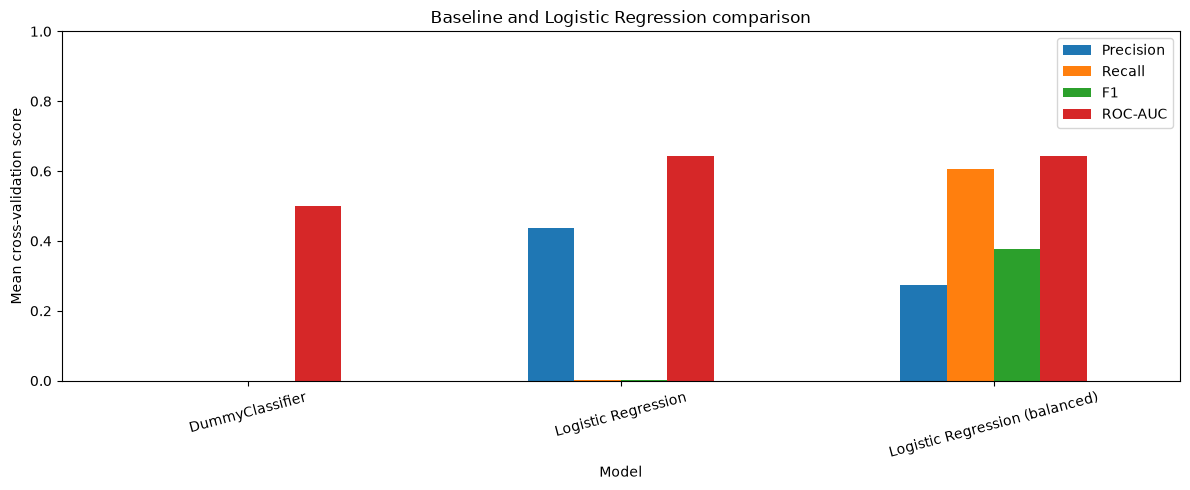

In [29]:
# Visualise the most relevant evaluation metrics
comparison[
    ["Precision", "Recall", "F1", "ROC-AUC"]
].plot(
    kind="bar",
    figsize=(12, 5)
)

plt.title("Baseline and Logistic Regression comparison")
plt.ylabel("Mean cross-validation score")
plt.xlabel("Model")
plt.ylim(0, 1)
plt.xticks(rotation=15)
plt.legend()
plt.tight_layout()
plt.show()

**Findings – 7.3:**

- The standard Logistic Regression model achieves a validation ROC-AUC of 0.6435, compared with 0.50 for the DummyClassifier. This indicates that the selected predictors contain useful information about arrival delay risk, although the model's discriminative ability remains limited.
- Despite an accuracy of 80.20%, the standard model identifies only 0.12% of delayed flights at the default classification threshold.
- Balanced class weighting increases recall from 0.0012 to 0.6057, while precision decreases from 0.4383 to 0.2734.
- The F1-score increases substantially from 0.0025 to 0.3768, while ROC-AUC remains essentially unchanged (0.6435 to 0.6437). This suggests that class weighting primarily changes the classification behaviour rather than substantially improving the model's ability to distinguish between delayed and non-delayed flights.
- From a business perspective, the balanced model identifies considerably more delayed flights but also generates more false-positive alerts. This represents a trade-off between proactive intervention and unnecessary resource allocation.
- The generalization gap is very small for both models (approximately 0.0015–0.0016), providing little indication of overfitting under the current random cross-validation strategy.
- These results will be compared with the tree-based models before selecting the final model configuration. The effect of different classification thresholds will be investigated during model evaluation.

### 7.4 Decision Tree

**What we do:** We train a Decision Tree classifier to predict whether a flight arrives at least 15 minutes late.

**Why:** Unlike Logistic Regression, Decision Trees can capture non-linear relationships and interactions between predictors without explicitly specifying them.

Our exploratory data analysis in Section 6 revealed that delay rates vary across scheduled departure hours, months and airports. In particular, the heatmap suggests a potential interaction between month and departure time.

A Decision Tree recursively divides the data into smaller groups based on predictor values, aiming to create groups with increasingly similar target values.

We first train a standard Decision Tree with limited depth and subsequently investigate whether balanced class weights improve the identification of delayed flights.

Since Decision Trees are based on splitting observations rather than calculating distances or linear combinations, standardization of numerical predictors is not required.

#### 7.4.1 Standard Decision Tree

We first train a Decision Tree using Gini impurity as the splitting criterion and a maximum depth of 5.

Limiting the depth controls model complexity and reduces the risk of overfitting. We initially use no class weighting to establish a reference point before investigating the effect of balanced class weights.

As with Logistic Regression, we evaluate the model using 3-fold stratified cross-validation.

In [30]:
# Standard Decision Tree
tree_model = Pipeline([
    ("preprocessing", preprocessor_unscaled),

    ("classifier", DecisionTreeClassifier(
        criterion="gini",
        max_depth=5,
        random_state=42
    ))
])

# Evaluate using cross-validation
tree_scores = evaluate_model(
    "Decision Tree",
    tree_model,
    X_train_raw,
    y_train
)

,Accuracy,Precision,Recall,F1,ROC-AUC,ROC-AUC SD,Training ROC-AUC,Generalization gap
Decision Tree,0.8021,0.3851,0.0001,0.0003,0.6433,0.0015,0.6443,0.001


#### 7.4.2 Decision Tree with balanced class weights

**What we do:** We train a second Decision Tree using balanced class weights.

**Why:** The Logistic Regression results demonstrated that class weighting substantially improved recall, while ROC-AUC remained almost unchanged.

We investigate whether a similar pattern occurs for the Decision Tree model.

Balanced class weighting increases the influence of delayed flights when calculating impurity and selecting splits. This may affect both the structure of the tree and its classification behaviour.

We keep the remaining hyperparameters unchanged to isolate the effect of class weighting.

In [31]:
# Decision Tree with balanced class weights
tree_balanced = Pipeline([
    ("preprocessing", preprocessor_unscaled),

    ("classifier", DecisionTreeClassifier(
        criterion="gini",
        max_depth=5,
        class_weight="balanced",
        random_state=42
    ))
])

# Evaluate using cross-validation
tree_balanced_scores = evaluate_model(
    "Decision Tree (balanced)",
    tree_balanced,
    X_train_raw,
    y_train
)

,Accuracy,Precision,Recall,F1,ROC-AUC,ROC-AUC SD,Training ROC-AUC,Generalization gap
Decision Tree (balanced),0.6122,0.2754,0.5874,0.3749,0.6428,0.0016,0.6437,0.001


#### 7.4.3 Comparison of Decision Tree models

We compare the standard and balanced Decision Tree models with the previously evaluated Logistic Regression models and DummyClassifier baseline.

The purpose is to investigate whether a non-linear model improves predictive performance and whether class weighting affects Decision Trees differently from Logistic Regression.

All models are evaluated using the same cross-validation folds and evaluation metrics.

In [32]:
# Compare all models evaluated so far
comparison = pd.DataFrame.from_dict(
    model_results,
    orient="index"
)

comparison.index.name = "Model"

display(comparison.round(4))

,Accuracy,Precision,Recall,F1,ROC-AUC,ROC-AUC SD,Training ROC-AUC,Generalization gap
Model,,,,,,,,
DummyClassifier,0.8021,0.0000,0.0000,0.0000,0.5000,0.0000,0.5000,0.0000
Logistic Regression,0.8020,0.4383,0.0012,0.0025,0.6435,0.0008,0.6450,0.0015
Logistic Regression (balanced),0.6033,0.2734,0.6057,0.3768,0.6437,0.0007,0.6452,0.0016
Decision Tree,0.8021,0.3851,0.0001,0.0003,0.6433,0.0015,0.6443,0.0010
Decision Tree (balanced),0.6122,0.2754,0.5874,0.3749,0.6428,0.0016,0.6437,0.0010


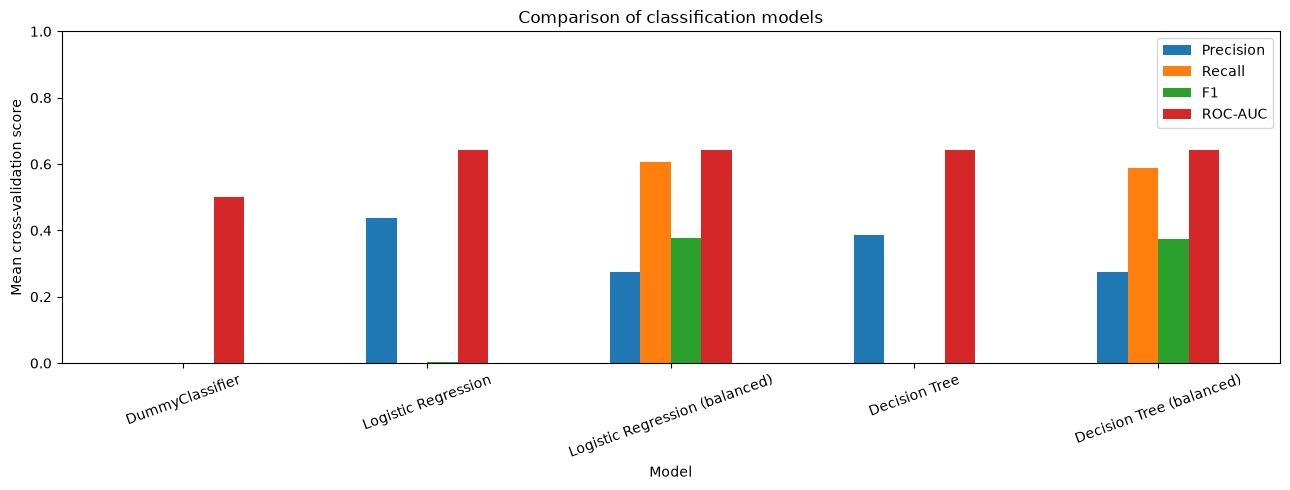

In [33]:
# Compare validation performance
comparison[
    ["Precision", "Recall", "F1", "ROC-AUC"]
].plot(
    kind="bar",
    figsize=(13, 5)
)

plt.title("Comparison of classification models")
plt.ylabel("Mean cross-validation score")
plt.xlabel("Model")
plt.ylim(0, 1)
plt.xticks(rotation=20)
plt.legend()
plt.tight_layout()
plt.show()

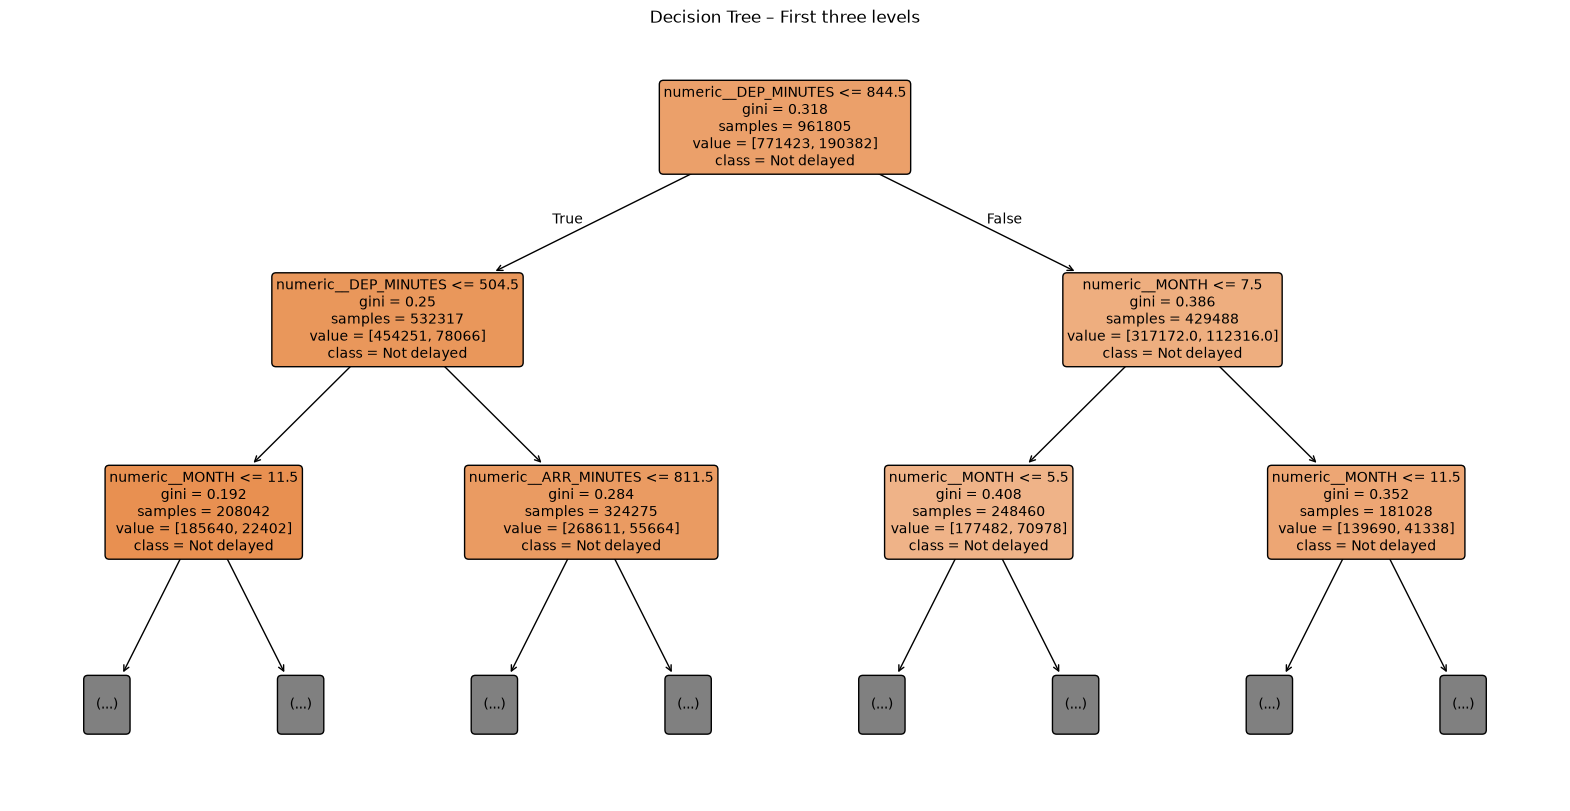

In [34]:
from sklearn.tree import plot_tree

# Fit the standard tree on the full training set
tree_model.fit(X_train_raw, y_train)

# Extract feature names after preprocessing
tree_features = (
    tree_model
    .named_steps["preprocessing"]
    .get_feature_names_out()
)

# Extract the fitted Decision Tree
fitted_tree = tree_model.named_steps["classifier"]

# Visualise the first three levels
plt.figure(figsize=(20, 10))

plot_tree(
    fitted_tree,
    feature_names=tree_features,
    class_names=["Not delayed", "Delayed"],
    filled=True,
    rounded=True,
    max_depth=2,
    fontsize=10
)

plt.title("Decision Tree – First three levels")
plt.show()

**Findings – 7.4:**

- The standard Decision Tree achieves a validation ROC-AUC of 0.6433, compared with 0.6435 for the standard Logistic Regression model. With a maximum depth of 5, the tree therefore does not improve discriminative performance relative to the linear model.
- The standard Decision Tree achieves a precision of 0.3851, recall of 0.0001 and F1-score of 0.0003. Like the standard Logistic Regression model, it almost never predicts delays at the default classification threshold.
- Balanced class weighting changes recall from 0.0001 to 0.5874, while precision changes from 0.3851 to 0.2754.
- The F1-score changes from 0.0003 to 0.3749, while ROC-AUC changes from 0.6433 to 0.6428. As with Logistic Regression, class weighting primarily changes classification behaviour rather than substantially improving the model's ability to distinguish between delayed and non-delayed flights.
- The generalization gaps for the standard and balanced Decision Trees are 0.0010 and 0.0010, respectively, providing little indication of overfitting under the current depth constraint.
- The tree visualisation reveals that DEP_MINUTES, MONTH and ARR_MINUTES are used in the initial splits, which is consistent with the temporal patterns identified in Section 6.
- Overall, the Decision Tree performs similarly to Logistic Regression under the current settings, so modelling non-linear relationships does not yet yield a clear performance gain.
- The effect of tree complexity will be investigated further in Section 7.6 and Section 7.7.
